# 02 - MobileNetV2 (Transfer Learning)
**Tugas: algoritma klasifikasi motif batik (deep learning)**

Mengikuti pipeline tim: data & split dari `data_utils.py`. Transfer learning dua tahap:
1. **Pelatihan head** — convolutional base MobileNetV2 (ImageNet) dibekukan, Adam 1e-3.
2. **Fine-tuning** — 40 lapisan terakhir dibuka, Adam 1e-5.

Input 224x224x3, preprocessing `x/127.5 - 1` (bawaan MobileNetV2), augmentasi flip/rotasi/zoom, validasi 15% dari data train (stratified, seed 42). Output: `models/mobilenetv2.h5` (diunggah ke Drive karena besar) + `models/metrics_mobilenetv2.json`.

In [1]:
import os, sys, json, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from data_utils import load_split, load_images

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

SEED = 42
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")

In [2]:
df, kelas, label2id = load_split()
labels = json.load(open("../models/labels.json", encoding="utf-8"))
assert kelas == labels, "Urutan kelas harus sama dengan models/labels.json"
NUM_CLASSES = len(labels)

train_df = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)
tr_df, val_df = train_test_split(train_df, test_size=0.15,
                                 stratify=train_df["label"], random_state=SEED)
X_train, y_train = load_images(tr_df.reset_index(drop=True), label2id)
X_val, y_val = load_images(val_df.reset_index(drop=True), label2id)
X_test, y_test = load_images(test_df, label2id)
print(f"Train {len(X_train)} | Validasi {len(X_val)} | Test {len(X_test)} | Kelas {NUM_CLASSES}")

Train 583 | Validasi 103 | Test 295 | Kelas 20


In [3]:
def make_ds(X, y, shuffle=False):
    y_cat = keras.utils.to_categorical(y, num_classes=NUM_CLASSES)
    ds = tf.data.Dataset.from_tensor_slices((X, y_cat))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test, y_test)

## 1. Arsitektur

In [4]:
data_aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="augmentasi")

base = keras.applications.MobileNetV2(include_top=False, weights="imagenet",
                                      input_shape=(224, 224, 3))
base.trainable = False  # dibekukan pada tahap 1

inputs = keras.Input(shape=(224, 224, 3))
x = data_aug(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)   # preprocess_input MobileNetV2
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs, name="mobilenetv2_batik")
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary(show_trainable=True)

Model: "mobilenetv2_batik"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentasi (Sequential)     │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ rescaling (Rescaling)       │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 20)            │     25,620 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,283,604 (8.71 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 2. Pelatihan dua tahap — **waktu pelatihan dicatat**

In [5]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=3, min_lr=1e-6, verbose=1),
]
t0 = time.perf_counter()
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)
print(f"Tahap 1 (head) selesai: {len(hist1.history['loss'])} epoch")

# Tahap 2: fine-tuning 40 lapisan terakhir dengan LR kecil
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
ft_cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=5,
                                       restore_best_weights=True, verbose=1)]
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=ft_cb)
train_sec = time.perf_counter() - t0
n_ep = len(hist1.history["loss"]) + len(hist2.history["loss"])
print(f"WAKTU PELATIHAN: {train_sec:.1f} s ({train_sec/60:.1f} menit), {n_ep} epoch total")

Epoch 1/30


C:\Users\HP\Documents\untar\semester 3\machine learning\uas\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/19 ━━━━━━━━━━━━━━━━━━━━ 1:23 5s/step - accuracy: 0.0938 - loss: 3.6083

 2/19 ━━━━━━━━━━━━━━━━━━━━ 4s 274ms/step - accuracy: 0.0625 - loss: 3.7844

 3/19 ━━━━━━━━━━━━━━━━━━━━ 4s 294ms/step - accuracy: 0.0625 - loss: 3.7775

 4/19 ━━━━━━━━━━━━━━━━━━━━ 4s 294ms/step - accuracy: 0.0547 - loss: 3.8293

... (481 outputs left out)

19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 414ms/step - accuracy: 0.4271 - loss: 1.9340 - val_accuracy: 0.3301 - val_loss: 2.4134


Epoch 9: early stopping


Restoring model weights from the end of the best epoch: 4.


WAKTU PELATIHAN: 170.9 s (2.8 menit), 23 epoch total


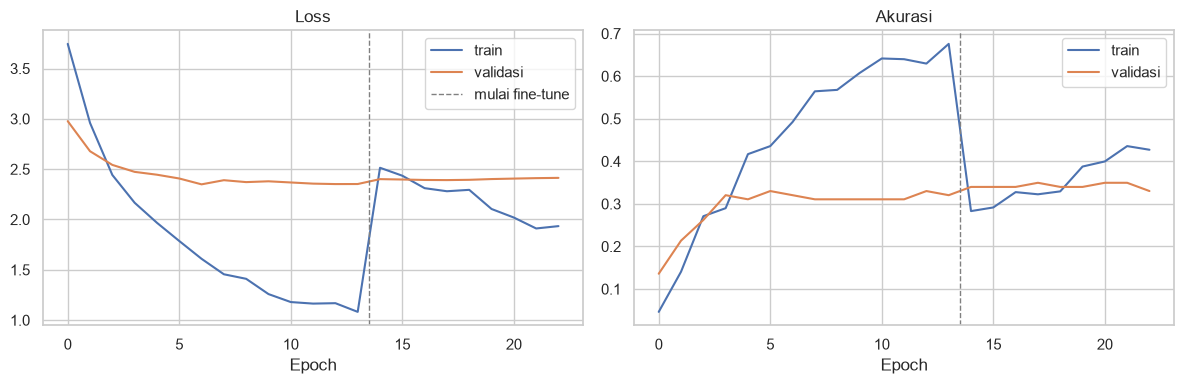

In [6]:
# Kurva pembelajaran (tahap 1 + fine-tuning)
h = {k: hist1.history[k] + hist2.history[k] for k in hist2.history if k in hist1.history}
ft_start = len(hist1.history["loss"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validasi")
axes[0].axvline(ft_start - 0.5, color="gray", ls="--", lw=1, label="mulai fine-tune")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h["accuracy"], label="train"); axes[1].plot(h["val_accuracy"], label="validasi")
axes[1].axvline(ft_start - 0.5, color="gray", ls="--", lw=1)
axes[1].set_title("Akurasi"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. Evaluasi data uji — akurasi, precision, recall, F1

AKURASI   : 0.3525
PRECISION : 0.3524 (macro)
RECALL    : 0.3552 (macro)
F1-SCORE  : 0.3319 (macro)
                   precision    recall  f1-score   support

       batik-bali       0.13      0.13      0.13        15
     batik-betawi       0.33      0.67      0.44        15
      batik-celup       0.55      0.73      0.63        15
batik-cendrawasih       0.67      0.13      0.22        15
     batik-ceplok       0.50      0.21      0.30        14
     batik-ciamis       0.25      0.07      0.11        15
    batik-garutan       0.17      0.13      0.15        15
  batik-gentongan       0.19      0.20      0.19        15
     batik-kawung       0.47      0.64      0.55        14
    batik-keraton       0.31      0.27      0.29        15
      batik-lasem       0.19      0.33      0.24        15
batik-megamendung       0.78      1.00      0.88        14
     batik-parang       0.47      0.60      0.53        15
 batik-pekalongan       0.19      0.20      0.19        15
   batik-prian

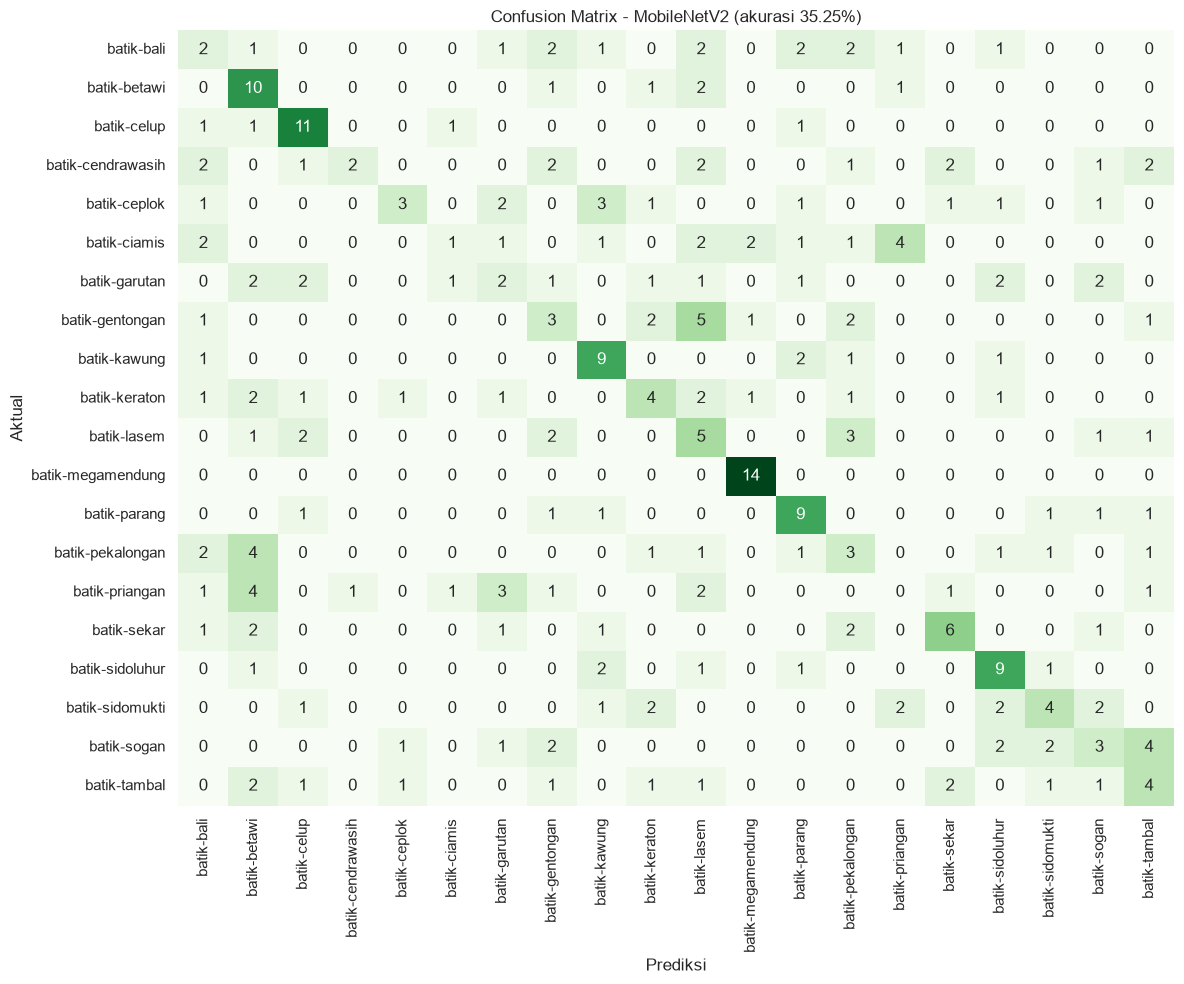

In [7]:
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
print(f"AKURASI   : {acc:.4f}")
print(f"PRECISION : {prec:.4f} (macro)")
print(f"RECALL    : {rec:.4f} (macro)")
print(f"F1-SCORE  : {f1:.4f} (macro)")
print(classification_report(y_test, y_pred, target_names=labels, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.title(f"Confusion Matrix - MobileNetV2 (akurasi {acc:.2%})")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

## 4. Simpan model + metrik
`mobilenetv2.h5` diunggah ke Drive bersama `resnet50.keras` (file besar, tidak masuk git sesuai kesepakatan tim).

In [8]:
model.save("../models/mobilenetv2.h5")
metrics = {
    "model": "MobileNetV2 (transfer learning + fine-tuning)",
    "accuracy": float(acc),
    "precision_macro": float(prec),
    "recall_macro": float(rec),
    "f1_macro": float(f1),
    "training_sec": float(train_sec),
    "epochs": int(n_ep),
    "history": {k: [float(v) for v in vs] for k, vs in h.items()},
    "n_train": int(len(y_train)), "n_val": int(len(y_val)), "n_test": int(len(y_test)),
    "labels": labels,
    "confusion_matrix": cm.tolist(),
    "classification_report": classification_report(y_test, y_pred, target_names=labels, output_dict=True, zero_division=0),
}
with open("../models/metrics_mobilenetv2.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("Tersimpan: models/mobilenetv2.h5 & models/metrics_mobilenetv2.json")

Tersimpan: models/mobilenetv2.h5 & models/metrics_mobilenetv2.json
